<a href="https://colab.research.google.com/github/fernandinhaalmeida84/Tech_Challenge_Fase_2/blob/main/notebooks/03_Modelagem_Preditiva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 3: Modelagem Preditiva**

## Onde estamos na história

No notebook 1 tratamos o cadastro e o histórico de crédito. No notebook 2 definimos o que é inadimplência: o **Inad90** (principal: atraso de 90 dias ou mais em algum mês) e o **Inad30** (alternativo: atraso de 30 dias ou mais). Agora chegou a hora de perguntar aos dados: **o perfil que o cliente declara no cadastro consegue prever quem vai ficar inadimplente?**

## O que fazemos aqui

1. Refazemos a junção das bases e os targets, exatamente como no notebook 2, sem criar arquivos intermediários.
2. Escolhemos o que entra e o que sai do modelo, para não dar ao algoritmo informação que ele não teria na hora da concessão.
3. Dividimos os clientes em **treino e teste por perfil**, para que perfis idênticos não fiquem dos dois lados.
4. Montamos o pré-processamento dentro de um `Pipeline`, calculando tudo só com o treino (sem vazamento).
5. Treinamos **dois modelos de natureza diferente** (Regressão Logística e Random Forest), tratando o desbalanceamento com `class_weight`.
6. Comparamos os modelos por **validação cruzada em grupos**, para os **dois targets**, apresentando os resultados como **faixas** e não como um número único.
7. Mostramos, com os próprios dados, por que a divisão por grupos importa.

O conjunto de teste fica **intocado** neste notebook. A avaliação final nele, a escolha do limiar de decisão, a importância das variáveis e as implicações de negócio ficam para o notebook 4.

## 1. Configuração e leitura das bases

Lemos as duas bases tratadas do notebook 1 direto da pasta `data/`, com `pd.read_csv`. O código procura a pasta a partir de onde o notebook está rodando; se não a encontrar (no Colab, por exemplo), clona o repositório.

Fixamos o `RANDOM_STATE = 42` logo na primeira célula e o usamos em **todos** os pontos aleatórios do notebook (divisão, validação cruzada e modelos), para que qualquer pessoa obtenha exatamente os mesmos resultados.

In [1]:
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)

URL_REPO = "https://github.com/fernandinhaalmeida84/Tech_Challenge_Fase_2.git"
COR_AZUL, COR_LARANJA, COR_CINZA = "#2F6DB5", "#E07B39", "#8A8F98"


def localizar_data():
    """Acha a pasta data/ (local ou clonada no Colab)."""
    for base_ in (Path.cwd(), Path.cwd().parent):
        for nome in ("data", "Data"):
            if (base_ / nome / "application_record_tratado.csv.gz").exists():
                return base_ / nome
    destino = Path("/content/Tech_Challenge_Fase_2")
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", URL_REPO, str(destino)], check=True)
    return destino / "data"


def br(n):
    """Inteiro com separador de milhar brasileiro."""
    return f"{int(n):,}".replace(",", ".")


def pct(x, casas=2):
    """Proporção como porcentagem brasileira."""
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def num(x, casas=3):
    """Número com vírgula decimal."""
    return f"{x:.{casas}f}".replace(".", ",")


DATA_DIR = localizar_data()
ARQ_CADASTRO = DATA_DIR / "application_record_tratado.csv.gz"
ARQ_CREDITO = DATA_DIR / "credit_record_tratado.csv.gz"

cadastro = pd.read_csv(ARQ_CADASTRO)
credito = pd.read_csv(ARQ_CREDITO, dtype={"STATUS": str})

print("Pasta de dados:", DATA_DIR.name)
print(f"Cadastro: {br(cadastro.shape[0])} linhas x {cadastro.shape[1]} colunas")
print(f"Histórico: {br(credito.shape[0])} linhas x {credito.shape[1]} colunas")

Pasta de dados: data
Cadastro: 438.463 linhas x 22 colunas
Histórico: 1.048.575 linhas x 3 colunas


## 2. Refazendo a junção e os targets

Repetimos aqui as seções 3 a 5 do notebook 2: marcamos, para cada cliente, se **em algum mês** o `STATUS` caiu na regra do Inad90 ou do Inad30, e juntamos ao cadastro pelo `ID` com junção **interna**. Fica só quem tem perfil **e** histórico, a única parte da base em que dá para medir inadimplência.

Repetir o código, em vez de gravar uma base intermediária, foi uma escolha consciente: cada notebook roda sozinho a partir das bases tratadas e a regra do target fica em um único lugar, sem risco de um arquivo antigo ficar desatualizado.

In [2]:
STATUS_INAD30 = ["1", "2", "3", "4", "5"]   # atraso a partir de 30 dias
STATUS_INAD90 = ["3", "4", "5"]             # atraso a partir de 90 dias

marcas = credito.assign(
    ATRASO_30=credito["STATUS"].isin(STATUS_INAD30),
    ATRASO_90=credito["STATUS"].isin(STATUS_INAD90),
)
alvo = (
    marcas.groupby("ID")
    .agg(
        Inad90=("ATRASO_90", "max"),
        Inad30=("ATRASO_30", "max"),
        MESES_HISTORICO=("MONTHS_BALANCE", "nunique"),
    )
    .reset_index()
)
alvo[["Inad90", "Inad30"]] = alvo[["Inad90", "Inad30"]].astype(int)

base = cadastro.merge(alvo, on="ID", how="inner", validate="one_to_one")

assert base["ID"].is_unique
assert (base["Inad90"] <= base["Inad30"]).all(), "Inad90 não pode existir sem Inad30"

resumo = pd.DataFrame({
    "Target": ["Inad90 (principal)", "Inad30 (alternativo)"],
    "Inadimplentes": [base["Inad90"].sum(), base["Inad30"].sum()],
    "Clientes": [len(base)] * 2,
})
resumo["Taxa"] = (resumo["Inadimplentes"] / resumo["Clientes"]).map(pct)
resumo["Inadimplentes"] = resumo["Inadimplentes"].map(br)
resumo["Clientes"] = resumo["Clientes"].map(br)

print(f"Clientes com cadastro e histórico: {br(len(base))} ({pct(len(base) / len(cadastro))} do cadastro)")
display(resumo)

Clientes com cadastro e histórico: 36.457 (8,31% do cadastro)


,Target,Inadimplentes,Clientes,Taxa
0,Inad90 (principal),302,36.457,"0,83%"
1,Inad30 (alternativo),4.291,36.457,"11,77%"


Os números batem com os do notebook 2: **36.457 clientes**, com **302 inadimplentes no Inad90 (0,83%)** e **4.291 no Inad30 (11,77%)**. Isso importa para tudo o que vem a seguir: o Inad90 é uma classe **muito rara**, então acurácia não serve (um modelo que sempre responde "bom pagador" acertaria 99,17% dos casos sem prever nada). Vamos medir os modelos com métricas que olham a classe rara.

## 3. O que entra e o que sai do modelo

Nem toda coluna da base pode ser variável do modelo. No notebook 2 já mostramos que `DAYS_BIRTH`, `DAYS_EMPLOYED` e `FLAG_MOBIL` não servem (uma repete a `Idade`, outra repete `Anos_Trabalhados` e `Desempregado ou aposentado`, e a terceira é constante), então aqui só **aplicamos** essa decisão. O que acrescentamos agora é a lista completa do que fica de fora, com o motivo de cada coluna: o que daria ao algoritmo uma informação que ele **não teria na hora de aprovar o cartão** (vazamento), o que não carrega informação e o que já está representado por outra coluna melhor:

In [3]:
DESCARTAR = {
    "ID": "Identificador do cliente, não descreve ninguém.",
    "Inad90": "É o target.",
    "Inad30": "É o target alternativo.",
    "MESES_HISTORICO": "Vazamento: só existe depois da aprovação e cresce junto com a inadimplência (efeito de exposição, visto no notebook 2).",
    "FLAG_MOBIL": "Constante: vale 1 para todos os clientes, não separa ninguém.",
    "PERFIL_ID": "Usado só para dividir treino e teste por grupo, nunca como variável.",
    "DAYS_BIRTH": "Já representada por Idade (em anos, mais legível).",
    "DAYS_EMPLOYED": "Já representada por Anos_Trabalhados e Desempregado ou aposentado (e traz o código especial 365243).",
}
display(pd.DataFrame({"Coluna descartada": list(DESCARTAR), "Motivo": list(DESCARTAR.values())}))

X = base.drop(columns=list(DESCARTAR)).copy()
X["Desempregado ou aposentado"] = X["Desempregado ou aposentado"].astype(int)   # True/False -> 1/0

alvos = {"Inad90": base["Inad90"], "Inad30": base["Inad30"]}
grupos = base["PERFIL_ID"]
colunas_cat = X.select_dtypes(exclude="number").columns.tolist()

print(f"Variáveis do modelo: {X.shape[1]} ({len(colunas_cat)} categóricas e {X.shape[1] - len(colunas_cat)} numéricas)")
print("Categóricas:", colunas_cat)

,Coluna descartada,Motivo
0,ID,"Identificador do cliente, não descreve ninguém."
1,Inad90,É o target.
2,Inad30,É o target alternativo.
3,MESES_HISTORICO,Vazamento: só existe depois da aprovação e cre...
4,FLAG_MOBIL,"Constante: vale 1 para todos os clientes, não ..."
5,PERFIL_ID,Usado só para dividir treino e teste por grupo...
6,DAYS_BIRTH,"Já representada por Idade (em anos, mais legív..."
7,DAYS_EMPLOYED,Já representada por Anos_Trabalhados e Desempr...


Variáveis do modelo: 17 (8 categóricas e 9 numéricas)
Categóricas: ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


Ficamos com **17 variáveis do cliente**, todas conhecidas no momento do pedido do cartão. `PERFIL_ID` sai das variáveis mas continua guardado em `grupos`: é ele que vai garantir uma divisão honesta, como mostramos a seguir. É o mesmo número a que chegamos no notebook 2.

## 4. Dividindo treino e teste por perfil

No notebook 1 vimos que cerca de 96% dos clientes dividem o perfil cadastral com outros (são só ~90 mil perfis distintos em mais de 438 mil clientes). Se uma divisão aleatória colocasse um cliente no treino e o "gêmeo" dele (mesmo perfil) no teste, o modelo estaria sendo avaliado em casos que ele já viu, e as métricas ficariam inflacionadas. Mostramos o tamanho desse efeito na seção 8.

Por isso dividimos **por grupo**: todos os clientes de um mesmo `PERFIL_ID` vão juntos para o treino ou juntos para o teste. Usamos o `StratifiedGroupKFold`, que além de respeitar os grupos mantém a proporção de inadimplentes parecida nos dois lados, algo essencial com uma classe tão rara. Pegamos uma das 5 partes (cerca de 20%) como **teste**, que fica guardado até o notebook 4.

Estratificamos pelo **Inad90** (o target principal). Assim os dois targets usam **o mesmo treino e o mesmo teste**, e podemos compará-los em igualdade de condições.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold

divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(divisor.split(X, alvos["Inad90"], grupos))

X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
g_treino, g_teste = grupos.iloc[idx_treino], grupos.iloc[idx_teste]
y_treino = {nome: y.iloc[idx_treino] for nome, y in alvos.items()}
y_teste = {nome: y.iloc[idx_teste] for nome, y in alvos.items()}

# Nenhum perfil pode aparecer nos dois lados
assert set(g_treino).isdisjoint(set(g_teste)), "Perfil vazou entre treino e teste"

def linha(nome, Xp, gp, yp):
    return {
        "Conjunto": nome,
        "Clientes": br(len(Xp)),
        "Perfis distintos": br(gp.nunique()),
        "Inad90 (casos)": br(yp["Inad90"].sum()),
        "Inad90 (taxa)": pct(yp["Inad90"].mean()),
        "Inad30 (casos)": br(yp["Inad30"].sum()),
        "Inad30 (taxa)": pct(yp["Inad30"].mean()),
    }

display(pd.DataFrame([
    linha("Treino", X_treino, g_treino, y_treino),
    linha("Teste", X_teste, g_teste, y_teste),
]))
print("Checagem ok: nenhum perfil aparece ao mesmo tempo no treino e no teste.")

,Conjunto,Clientes,Perfis distintos,Inad90 (casos),Inad90 (taxa),Inad30 (casos),Inad30 (taxa)
0,Treino,29.165,7.788,242,"0,83%",3.431,"11,76%"
1,Teste,7.292,1.940,60,"0,82%",860,"11,79%"


Checagem ok: nenhum perfil aparece ao mesmo tempo no treino e no teste.


**Leitura:** os dois conjuntos ficaram praticamente iguais em perfil de risco: **0,83% de Inad90 no treino e 0,82% no teste**, e **11,76% e 11,79% de Inad30**. A estratificação funcionou. Também não há perfil em comum: o treino tem 7.788 perfis distintos e o teste, 1.940, e a checagem automática confirmou que nenhum aparece nos dois lados.

Um ponto de atenção que acompanhará o resto do projeto: o teste tem **apenas 60 inadimplentes no Inad90** (e o treino, 242). Com tão poucos casos, uma métrica calculada em um único conjunto é instável. Por isso, daqui em diante apresentamos os resultados como **faixas** e não como um número único.

## 5. Pré-processamento dentro de um `Pipeline`

Aplicamos agora os tratamentos que, no notebook 1, deixamos combinados para a etapa de modelagem. Todos entram em um `Pipeline`, o que garante que cada parâmetro (limite de corte, categorias raras, média e desvio) seja **calculado só com os dados de treino** e depois apenas aplicado ao teste. Dentro da validação cruzada, isso vale para cada rodada.

| Variável | Tratamento | Por quê |
|---|---|---|
| `Anos_Trabalhados` | *Winsorization*: valores acima de Q3 + 1,5 x IQR do treino viram esse limite | Pouco mais de 5% dos clientes são outliers de tempo de serviço; limitamos sem descartar ninguém |
| `CNT_FAM_MEMBERS` | Teto de 5 membros | Famílias com mais de 5 pessoas são poucas e algumas parecem erro de coleta |
| `AMT_INCOME_TOTAL` | `log1p` | A renda é muito assimétrica; o log reduz o peso de rendas extremas |
| Categóricas | *One-hot* com categorias raras (menos de 1% do treino) agrupadas em uma só | Categorias como `Student` e `Academic degree` têm pouquíssimos casos para o modelo aprender algo confiável |
| Demais numéricas | Sem tratamento extra | `Idade` não tem outliers |
| Normalização (média 0, desvio 1) | **Só para a Regressão Logística** | Modelos lineares dependem da escala das variáveis; árvores não, e a normalização só atrapalharia a leitura delas |

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


class Winsorizador(BaseEstimator, TransformerMixin):
    """Limita o valor máximo a Q3 + 1,5 x IQR, com o limite aprendido só no treino."""

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        self.limite_ = q3 + 1.5 * (q3 - q1)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.limite_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def limitar_em_5(a):
    return np.minimum(a, 5)


def montar_preprocessador(escalar):
    """Pré-processamento do notebook 1. `escalar=True` acrescenta a normalização (modelos lineares)."""

    def etapas(*passos):
        passos = list(passos)
        if escalar:
            passos.append(("escala", StandardScaler()))
        return Pipeline(passos)

    return ColumnTransformer(
        [
            ("anos", etapas(("winsor", Winsorizador())), ["Anos_Trabalhados"]),
            ("familia", etapas(("teto", FunctionTransformer(limitar_em_5, feature_names_out="one-to-one"))), ["CNT_FAM_MEMBERS"]),
            ("renda", etapas(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))), ["AMT_INCOME_TOTAL"]),
            ("numericas", StandardScaler() if escalar else "passthrough", ["Idade", "CNT_CHILDREN"]),
            ("binarias", "passthrough", ["FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "Desempregado ou aposentado"]),
            ("categoricas", OneHotEncoder(drop="if_binary", min_frequency=0.01,
                                          handle_unknown="infrequent_if_exist", sparse_output=False), colunas_cat),
        ],
        verbose_feature_names_out=False,
    )


# Demonstração: ajustamos só com o treino e conferimos o que foi aprendido
prep_demo = montar_preprocessador(escalar=True).fit(X_treino)
limite_anos = prep_demo.named_transformers_["anos"]["winsor"].limite_[0]
print(f"Limite da winsorização de Anos_Trabalhados (calculado no treino): {num(limite_anos, 2)} anos")
print(f"Variáveis que o modelo enxerga depois do pré-processamento: {len(prep_demo.get_feature_names_out())}")

codificador = prep_demo.named_transformers_["categoricas"]
raras = {
    col: list(cats)
    for col, cats in zip(colunas_cat, codificador.infrequent_categories_)
    if cats is not None
}
print("\nCategorias raras agrupadas (menos de 1% do treino):")
for col, cats in raras.items():
    print(f"  {col}: {', '.join(cats)}")

Limite da winsorização de Anos_Trabalhados (calculado no treino): 19,61 anos
Variáveis que o modelo enxerga depois do pré-processamento: 46

Categorias raras agrupadas (menos de 1% do treino):
  NAME_INCOME_TYPE: Student
  NAME_EDUCATION_TYPE: Academic degree
  NAME_HOUSING_TYPE: Co-op apartment, Office apartment
  OCCUPATION_TYPE: HR staff, IT staff, Low-skill Laborers, Realty agents, Secretaries, Waiters/barmen staff


**Leitura:** o pré-processamento aprendeu tudo só com o treino. O limite de corte de `Anos_Trabalhados` ficou em **19,61 anos**, quase igual aos 19,72 que encontramos no cadastro inteiro (notebook 1), sinal de que o treino representa bem a base. Depois do *one-hot*, o modelo enxerga **46 colunas**.

Os agrupamentos de categorias raras são os esperados: `Student` e `Academic degree` (os exemplos que já tínhamos apontado) e mais algumas moradias e ocupações pequenas. Cada uma vira uma categoria "rara" única, em vez de o modelo tentar aprender algo com uma dezena de clientes.

## 6. Os modelos e o desbalanceamento

Escolhemos **dois modelos de natureza diferente**, para ver se a conclusão depende do tipo de algoritmo:

- **Regressão Logística:** modelo linear. Simples, rápido e fácil de explicar: cada variável ganha um peso que aumenta ou diminui o risco. É o nosso modelo "interpretável".
- **Random Forest:** conjunto de várias árvores de decisão. Captura combinações e relações não lineares entre as variáveis, ao custo de ser mais difícil de explicar. É o nosso modelo "flexível".

Incluímos também um **baseline**: um modelo que ignora o perfil e sempre devolve a taxa média de inadimplência. Ele define o piso: qualquer modelo que valha a pena precisa vencê-lo.

**Como tratamos o desbalanceamento:** com `class_weight`. O algoritmo passa a dar mais peso ao erro na classe rara (um inadimplente mal classificado "custa" muito mais que um bom cliente mal classificado, na proporção inversa das frequências). Preferimos isso à reamostragem porque **não cria nem descarta dados**, roda dentro do `Pipeline` sem risco de vazamento e não depende de bibliotecas extras. Na Regressão Logística usamos `balanced`; na Random Forest, `balanced_subsample`, que recalcula os pesos dentro de cada árvore.

**Hiperparâmetros:** testamos uma grade pequena e fixa para cada modelo (força da regularização na Regressão Logística; profundidade e tamanho mínimo das folhas na Random Forest). Árvores livres demais decoram o treino, e com poucos inadimplentes isso é um risco real.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression


def montar_modelos():
    """Devolve {nome: (pipeline, grade de hiperparâmetros)}."""
    return {
        "Baseline (taxa média)": (
            Pipeline([("prep", montar_preprocessador(False)),
                      ("modelo", DummyClassifier(strategy="prior"))]),
            {"modelo__strategy": ["prior"]},
        ),
        "Regressão Logística": (
            Pipeline([("prep", montar_preprocessador(True)),
                      ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000,
                                                    random_state=RANDOM_STATE))]),
            {"modelo__C": [0.001, 0.01, 0.1, 1]},
        ),
        "Random Forest": (
            Pipeline([("prep", montar_preprocessador(False)),
                      ("modelo", RandomForestClassifier(n_estimators=150, class_weight="balanced_subsample",
                                                        random_state=RANDOM_STATE, n_jobs=-1))]),
            {"modelo__max_depth": [8, None], "modelo__min_samples_leaf": [10, 30]},
        ),
    }


modelos = montar_modelos()
for nome, (pipe, grade) in modelos.items():
    print(f"{nome}: {int(np.prod([len(v) for v in grade.values()]))} configuração(ões) na grade")

Baseline (taxa média): 1 configuração(ões) na grade
Regressão Logística: 4 configuração(ões) na grade
Random Forest: 4 configuração(ões) na grade


## 7. Validação cruzada por grupo

Com apenas **242 inadimplentes no treino** (Inad90), qualquer número isolado é instável: bastaria trocar alguns clientes de lado para a métrica mudar. Por isso avaliamos cada modelo por **validação cruzada em 5 partes**, também por grupo e estratificada: o treino é dividido em 5, o modelo aprende em 4 e é avaliado na quinta, e repetimos até todas as partes serem usadas como avaliação. Assim obtemos 5 resultados por modelo e mostramos a **média e a faixa (mínimo a máximo)**.

**Métricas e por que as escolhemos:**

- **AUC-PR (principal):** mede o equilíbrio entre pegar inadimplentes e não gerar alarmes falsos, olhando só a classe rara. Em problemas desbalanceados, é mais honesta que a AUC-ROC. O valor de referência é a própria taxa de inadimplentes (0,83% no Inad90): um modelo sem poder preditivo fica nesse patamar.
- **AUC-ROC:** mede a capacidade de **ordenar** os clientes do menos para o mais arriscado. Vale 0,5 para um sorteio e 1 para uma ordenação perfeita.
- **Recall:** dos inadimplentes reais, quantos o modelo pegou. É o custo de deixar passar um mau pagador.
- **Precisão:** dos clientes que o modelo apontou como risco, quantos realmente eram. É o custo de recusar um bom cliente.
- **F1:** resume recall e precisão em um número.
- **Acurácia não entra**, pelo motivo mostrado na seção 2.

Recall, precisão e F1 dependem de um **limiar de decisão** (a nota de corte para chamar alguém de "risco"). Aqui usamos o corte padrão de 0,5 sobre as probabilidades com `class_weight`, só para comparar os modelos entre si. A escolha do limiar com critério de negócio é o tema do notebook 4.

A grade de hiperparâmetros é avaliada nessas mesmas partes e escolhemos a melhor configuração pelo **AUC-PR**. Como isso é uma escolha feita sobre o treino, ela é levemente otimista, e é por isso que o teste fica reservado: só ele dá o resultado honesto.

In [7]:
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV

# zero_division=0: quando o modelo não aponta ninguém como risco (caso do baseline), a precisão vale 0
METRICAS = {
    "AUC-PR": "average_precision",
    "AUC-ROC": "roc_auc",
    "Recall": make_scorer(recall_score, zero_division=0),
    "Precisão": make_scorer(precision_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
}
N_PARTES = 5

buscas = {}   # buscas[alvo][modelo] = GridSearchCV já ajustado (e reajustado no treino todo)
for alvo_nome in alvos:
    buscas[alvo_nome] = {}
    cv = StratifiedGroupKFold(n_splits=N_PARTES, shuffle=True, random_state=RANDOM_STATE)
    for nome, (pipe, grade) in montar_modelos().items():
        busca = GridSearchCV(pipe, grade, scoring=METRICAS, refit="AUC-PR", cv=cv, n_jobs=-1)
        busca.fit(X_treino, y_treino[alvo_nome], groups=g_treino)
        buscas[alvo_nome][nome] = busca
        print(f"{alvo_nome} | {nome}: AUC-PR médio = {num(busca.best_score_)}")


def faixa(busca, metrica):
    """(média, mínimo, máximo) da métrica nas 5 partes, para a melhor configuração."""
    valores = np.array([busca.cv_results_[f"split{k}_test_{metrica}"][busca.best_index_] for k in range(N_PARTES)])
    return valores.mean(), valores.min(), valores.max()


def tabela_cv(alvo_nome):
    linhas = []
    for nome, busca in buscas[alvo_nome].items():
        reg = {"Modelo": nome}
        reg["Melhor configuração"] = ", ".join(f"{k.split('__')[1]}={v}" for k, v in busca.best_params_.items()) \
            if nome != "Baseline (taxa média)" else "-"
        for metrica in METRICAS:
            m, lo, hi = faixa(busca, metrica)
            reg[metrica] = f"{num(m)} ({num(lo)} a {num(hi)})"
        linhas.append(reg)
    return pd.DataFrame(linhas)


for alvo_nome in alvos:
    prevalencia = y_treino[alvo_nome].mean()
    print(f"\n=== {alvo_nome} | taxa de inadimplentes no treino: {pct(prevalencia)} | valores: média (mínimo a máximo nas 5 partes) ===")
    display(tabela_cv(alvo_nome))

Inad90 | Baseline (taxa média): AUC-PR médio = 0,008
Inad90 | Regressão Logística: AUC-PR médio = 0,034
Inad90 | Random Forest: AUC-PR médio = 0,037
Inad30 | Baseline (taxa média): AUC-PR médio = 0,118
Inad30 | Regressão Logística: AUC-PR médio = 0,134
Inad30 | Random Forest: AUC-PR médio = 0,129

=== Inad90 | taxa de inadimplentes no treino: 0,83% | valores: média (mínimo a máximo nas 5 partes) ===


,Modelo,Melhor configuração,AUC-PR,AUC-ROC,Recall,Precisão,F1
0,Baseline (taxa média),-,"0,008 (0,008 a 0,009)","0,500 (0,500 a 0,500)","0,000 (0,000 a 0,000)","0,000 (0,000 a 0,000)","0,000 (0,000 a 0,000)"
1,Regressão Logística,C=1,"0,034 (0,015 a 0,048)","0,579 (0,521 a 0,631)","0,425 (0,354 a 0,500)","0,010 (0,008 a 0,012)","0,020 (0,017 a 0,024)"
2,Random Forest,"max_depth=None, min_samples_leaf=10","0,037 (0,018 a 0,070)","0,593 (0,557 a 0,651)","0,025 (0,000 a 0,062)","0,060 (0,000 a 0,231)","0,033 (0,000 a 0,098)"



=== Inad30 | taxa de inadimplentes no treino: 11,76% | valores: média (mínimo a máximo nas 5 partes) ===


,Modelo,Melhor configuração,AUC-PR,AUC-ROC,Recall,Precisão,F1
0,Baseline (taxa média),-,"0,118 (0,117 a 0,118)","0,500 (0,500 a 0,500)","0,000 (0,000 a 0,000)","0,000 (0,000 a 0,000)","0,000 (0,000 a 0,000)"
1,Regressão Logística,C=1,"0,134 (0,131 a 0,140)","0,520 (0,499 a 0,538)","0,467 (0,427 a 0,497)","0,125 (0,119 a 0,129)","0,197 (0,186 a 0,204)"
2,Random Forest,"max_depth=8, min_samples_leaf=30","0,129 (0,123 a 0,138)","0,519 (0,506 a 0,531)","0,294 (0,242 a 0,376)","0,126 (0,115 a 0,139)","0,176 (0,158 a 0,203)"


**O que as tabelas dizem:**

- **Inad90 (principal):** os dois modelos vencem o baseline, mas por pouco. O AUC-PR médio é de **0,034 (Regressão Logística) e 0,037 (Random Forest)**, contra 0,008 do baseline: cerca de 4 vezes melhor que ignorar o perfil, mas em um patamar absoluto muito baixo. A **AUC-ROC fica em 0,58 e 0,59**: o modelo ordena os clientes só um pouco melhor que um sorteio (0,5). As faixas são largas e **se sobrepõem** (a do Random Forest vai de 0,018 a 0,070 no AUC-PR), então a diferença entre os dois modelos é um **empate técnico**.
- **Recall e precisão (corte 0,5):** a Regressão Logística pega **42,5% dos inadimplentes**, mas com precisão de **1,0%**: para cada 100 clientes apontados como risco, só 1 realmente fica inadimplente. O Random Forest, nesse mesmo corte, quase não aponta ninguém (recall de 2,5%). Isso **não é falta de qualidade do modelo, é efeito do corte 0,5**: as probabilidades do Random Forest raramente chegam a esse valor. Por isso o limiar precisa ser escolhido com critério de negócio (notebook 4).
- **Inad30 (alternativo):** aqui as faixas são **bem estreitas** (há 3.431 casos no treino), então o resultado é confiável, e ele é desanimador: AUC-PR de 0,134 e 0,129 contra 0,118 do baseline, e **AUC-ROC de 0,520 e 0,519, praticamente um sorteio** (a faixa da Regressão Logística, de 0,499 a 0,538, inclui 0,5).

**Conclusão parcial:** o perfil cadastral tem **sinal fraco** para prever inadimplência. Há algum sinal para o atraso grave (Inad90) e quase nenhum para o atraso leve (Inad30). Dar mais exemplos ao modelo, como o Inad30 faz, não resolveu: o limite parece estar na informação disponível, não no algoritmo.

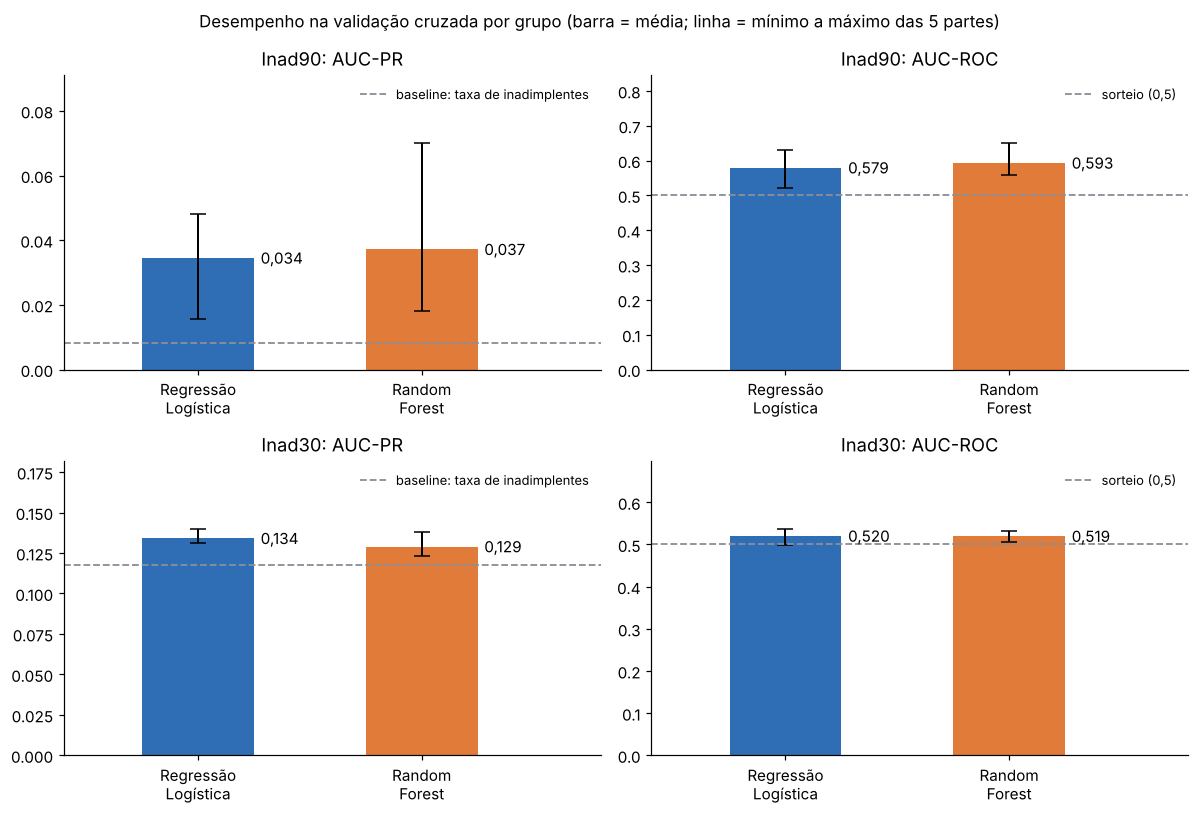

In [8]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 7.5))
modelos_plot = ["Regressão Logística", "Random Forest"]
cores = [COR_AZUL, COR_LARANJA]

for i, alvo_nome in enumerate(alvos):
    for j, (metrica, ref, rotulo_ref) in enumerate([
        ("AUC-PR", y_treino[alvo_nome].mean(), "baseline: taxa de inadimplentes"),
        ("AUC-ROC", 0.5, "sorteio (0,5)"),
    ]):
        ax = eixos[i, j]
        for k, nome in enumerate(modelos_plot):
            m, lo, hi = faixa(buscas[alvo_nome][nome], metrica)
            ax.bar(k, m, color=cores[k], width=0.5)
            ax.errorbar(k, m, yerr=[[m - lo], [hi - m]], color="black", capsize=5, linewidth=1.3)
            ax.text(k + 0.28, m, num(m), va="center", fontsize=10)
        ax.axhline(ref, color=COR_CINZA, linestyle="--", linewidth=1.2, label=rotulo_ref)
        topo = max(faixa(buscas[alvo_nome][n], metrica)[2] for n in modelos_plot)
        ax.set_ylim(0, max(topo, ref) * 1.3)
        ax.legend(frameon=False, loc="upper right", fontsize=8.5)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Regressão\nLogística", "Random\nForest"])
        ax.set_title(f"{alvo_nome}: {metrica}")
        ax.set_xlim(-0.6, 1.8)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Desempenho na validação cruzada por grupo (barra = média; linha = mínimo a máximo das 5 partes)", fontsize=11)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** as barras são as médias e as linhas pretas, o mínimo e o máximo nas 5 partes; a linha cinza tracejada é a referência (taxa de inadimplentes no AUC-PR; 0,5 na AUC-ROC). No Inad90 as barras passam da linha, mas as faixas são longas e quase iguais entre os modelos. No Inad30, as barras da AUC-ROC praticamente **encostam na linha do sorteio**. Nenhum dos dois algoritmos se destaca, o que reforça a leitura de que a limitação está nos dados.

## 8. Por que dividimos por perfil: a prova nos dados

Prometemos mostrar o efeito de não agrupar. Repetimos a validação cruzada com **exatamente os mesmos modelos e hiperparâmetros**, mudando só uma coisa: na versão "sem grupo", os clientes são sorteados individualmente, de modo que o "gêmeo" de um cliente do treino pode cair na parte de avaliação.

In [9]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

linhas = []
for alvo_nome in alvos:
    for nome in ["Regressão Logística", "Random Forest"]:
        melhor = buscas[alvo_nome][nome].best_estimator_
        for rotulo, cv, params in [
            ("Sem grupo (sorteio individual)", StratifiedKFold(N_PARTES, shuffle=True, random_state=RANDOM_STATE), None),
            ("Com grupo (por perfil)", StratifiedGroupKFold(N_PARTES, shuffle=True, random_state=RANDOM_STATE), g_treino),
        ]:
            res = cross_validate(clone(melhor), X_treino, y_treino[alvo_nome], cv=cv, groups=params,
                                 scoring={"AUC-PR": "average_precision", "AUC-ROC": "roc_auc"}, n_jobs=-1)
            linhas.append({"Target": alvo_nome, "Modelo": nome, "Validação": rotulo,
                           "AUC-PR": res["test_AUC-PR"].mean(), "AUC-ROC": res["test_AUC-ROC"].mean()})

comparacao = pd.DataFrame(linhas)
exibir = comparacao.copy()
exibir["AUC-PR"] = exibir["AUC-PR"].map(num)
exibir["AUC-ROC"] = exibir["AUC-ROC"].map(num)
display(exibir)

,Target,Modelo,Validação,AUC-PR,AUC-ROC
0,Inad90,Regressão Logística,Sem grupo (sorteio individual),"0,041","0,629"
1,Inad90,Regressão Logística,Com grupo (por perfil),"0,034","0,579"
2,Inad90,Random Forest,Sem grupo (sorteio individual),"0,175","0,772"
3,Inad90,Random Forest,Com grupo (por perfil),"0,037","0,593"
4,Inad30,Regressão Logística,Sem grupo (sorteio individual),"0,148","0,548"
5,Inad30,Regressão Logística,Com grupo (por perfil),"0,134","0,520"
6,Inad30,Random Forest,Sem grupo (sorteio individual),"0,233","0,646"
7,Inad30,Random Forest,Com grupo (por perfil),"0,129","0,519"


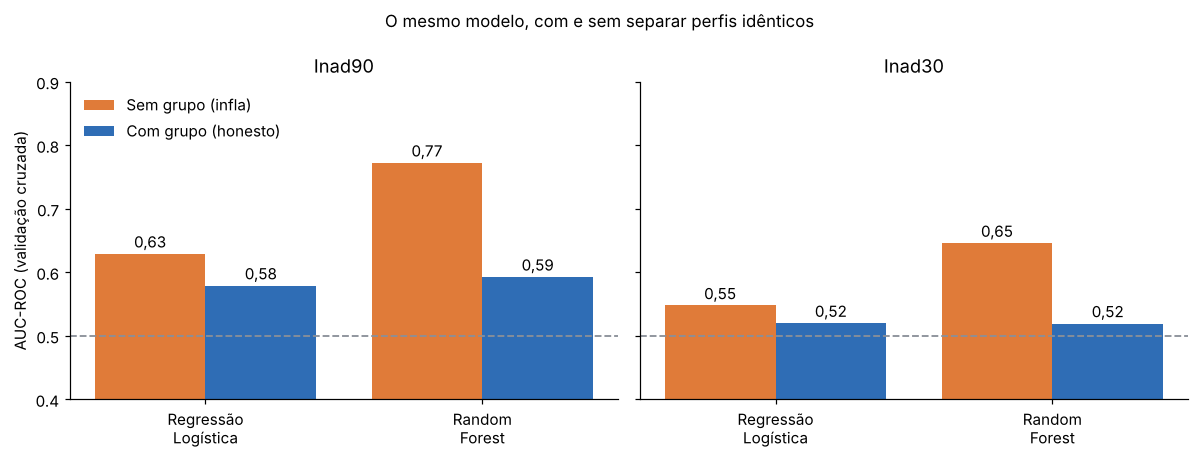

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, alvo_nome in zip(eixos, alvos):
    sub = comparacao[comparacao["Target"] == alvo_nome]
    x = np.arange(2)
    sem = sub[sub["Validação"].str.startswith("Sem")].set_index("Modelo").loc[["Regressão Logística", "Random Forest"], "AUC-ROC"]
    com = sub[sub["Validação"].str.startswith("Com")].set_index("Modelo").loc[["Regressão Logística", "Random Forest"], "AUC-ROC"]
    ax.bar(x - 0.2, sem.values, width=0.4, color=COR_LARANJA, label="Sem grupo (infla)")
    ax.bar(x + 0.2, com.values, width=0.4, color=COR_AZUL, label="Com grupo (honesto)")
    for xi, v in zip(x - 0.2, sem.values):
        ax.text(xi, v + 0.01, num(v, 2), ha="center", fontsize=10)
    for xi, v in zip(x + 0.2, com.values):
        ax.text(xi, v + 0.01, num(v, 2), ha="center", fontsize=10)
    ax.axhline(0.5, color=COR_CINZA, linestyle="--", linewidth=1.2)
    ax.set_xticks(x)
    ax.set_xticklabels(["Regressão\nLogística", "Random\nForest"])
    ax.set_title(alvo_nome)
    ax.set_ylim(0.4, 0.9)
    ax.spines[["top", "right"]].set_visible(False)
eixos[0].set_ylabel("AUC-ROC (validação cruzada)")
eixos[0].legend(frameon=False, loc="upper left")
fig.suptitle("O mesmo modelo, com e sem separar perfis idênticos", fontsize=11)
plt.tight_layout()
plt.show()

**Leitura:** o efeito é enorme no Random Forest. Sem separar os perfis, ele parece ótimo: **AUC-ROC de 0,77 no Inad90** (AUC-PR de 0,175, mais de 4 vezes o valor honesto de 0,037) e 0,65 no Inad30. Com a divisão por perfil, esses números caem para **0,59 e 0,52**. O motivo é que, entre os clientes de mesmo perfil, o "gêmeo" que ficou no treino entrega a resposta do que está na avaliação: o modelo **decora perfis em vez de aprender padrões**. A Regressão Logística, por ser simples demais para decorar, sofre bem menos (de 0,63 para 0,58 no Inad90).

Esta é a razão de toda a nossa cautela com o `PERFIL_ID`: sem ela, teríamos apresentado um modelo "com AUC de 0,77" que **não se sustentaria diante de clientes novos**. Os números da seção 7, mais modestos, são os que representam o que acontece na vida real.

## 9. Qual modelo levamos para o notebook 4

Para cada target, comparamos o AUC-PR médio dos dois modelos e o tamanho da faixa entre as partes. O modelo de cada target já foi **reajustado com o treino inteiro** pelo `GridSearchCV`, e fica guardado em `modelos_finais`.

In [11]:
modelos_finais = {}
linhas = []
for alvo_nome in alvos:
    candidatos = {n: b for n, b in buscas[alvo_nome].items() if n != "Baseline (taxa média)"}
    melhor_nome = max(candidatos, key=lambda n: candidatos[n].best_score_)
    modelos_finais[alvo_nome] = {n: b.best_estimator_ for n, b in candidatos.items()}
    m_a, lo_a, hi_a = faixa(candidatos["Regressão Logística"], "AUC-PR")
    m_b, lo_b, hi_b = faixa(candidatos["Random Forest"], "AUC-PR")
    desvio_a = np.std([candidatos["Regressão Logística"].cv_results_[f"split{k}_test_AUC-PR"][candidatos["Regressão Logística"].best_index_] for k in range(N_PARTES)])
    desvio_b = np.std([candidatos["Random Forest"].cv_results_[f"split{k}_test_AUC-PR"][candidatos["Random Forest"].best_index_] for k in range(N_PARTES)])
    diferenca = abs(m_a - m_b)
    linhas.append({
        "Target": alvo_nome,
        "AUC-PR Reg. Logística": num(m_a),
        "AUC-PR Random Forest": num(m_b),
        "Diferença": num(diferenca),
        "Variação entre partes (desvio)": num(max(desvio_a, desvio_b)),
        "Maior AUC-PR": melhor_nome,
        "Diferença maior que a variação?": "Sim" if diferenca > max(desvio_a, desvio_b) else "Não (empate técnico)",
    })

display(pd.DataFrame(linhas))
print("Modelos finais guardados em memória para os dois targets (Regressão Logística e Random Forest).")

,Target,AUC-PR Reg. Logística,AUC-PR Random Forest,Diferença,Variação entre partes (desvio),Maior AUC-PR,Diferença maior que a variação?
0,Inad90,"0,034","0,037","0,003","0,020",Random Forest,Não (empate técnico)
1,Inad30,"0,134","0,129","0,005","0,006",Regressão Logística,Não (empate técnico)


Modelos finais guardados em memória para os dois targets (Regressão Logística e Random Forest).


**Resultado da comparação:** nos dois targets, a diferença entre Regressão Logística e Random Forest é **menor que a variação entre as partes da validação cruzada** (um empate técnico). Por isso não "coroamos" um vencedor agora: levamos **os dois modelos, nos dois targets**, para o notebook 4, onde eles enfrentam o teste e são comparados também pela interpretabilidade, que favorece a Regressão Logística.

## 10. Resumo e próximo passo

**O que fizemos**

- Refizemos a junção e os targets do notebook 2 (36.457 clientes; Inad90 = 302 casos, 0,83%; Inad30 = 4.291, 11,77%).
- Descartamos as colunas que vazariam informação ou não informam nada (`ID`, `MESES_HISTORICO`, `FLAG_MOBIL`, `PERFIL_ID`, targets e as colunas `DAYS_*` já representadas por outras) e ficamos com 17 variáveis do cliente.
- Dividimos treino e teste **por perfil e com estratificação**, garantindo que nenhum perfil esteja nos dois lados. O teste (7.292 clientes, 60 inadimplentes no Inad90) segue **intocado**.
- Aplicamos winsorização, teto de família, `log1p` na renda, agrupamento de categorias raras e one-hot **dentro de um `Pipeline`**, aprendidos só com o treino, e normalizamos só para a Regressão Logística.
- Treinamos **dois modelos distintos** (Regressão Logística e Random Forest), com `class_weight` para o desbalanceamento, e os comparamos por validação cruzada em grupos, com `RANDOM_STATE = 42` em todos os pontos aleatórios.
- Mostramos, com os dados, que ignorar o agrupamento por perfil inflaria o Random Forest de 0,59 para 0,77 de AUC-ROC.

**O que encontramos**

- O perfil cadastral tem **sinal fraco**: AUC-ROC de cerca de 0,58 a 0,59 para o atraso grave (Inad90) e de cerca de 0,52 (sorteio) para o atraso leve (Inad30).
- Os dois algoritmos empatam tecnicamente. Esse não é um problema de escolha de modelo, e sim de informação disponível.

**O que levamos para o notebook 4**

- Recriamos os dois modelos com este mesmo código (cada notebook roda sozinho) e os avaliamos **uma única vez no teste**, com faixas, já que há só 60 inadimplentes.
- Escolhemos o **limiar de decisão pelo custo de negócio**, mostrando uma **curva de sensibilidade** para várias relações de custo entre aprovar um inadimplente e recusar um bom cliente.
- Analisamos a **importância das variáveis** (coeficientes e importância por permutação) e traduzimos tudo para **implicações de negócio**: com um sinal tão fraco, o modelo serve como **apoio de triagem** na decisão de crédito e não como decisor único.